Jumlah foto: 21
OCR tersedia: False | OCR aktif: False

Distribusi ground truth:


,jumlah_foto
kondisi,
cahaya,4
ideal,6
sudut,7
sulit,4


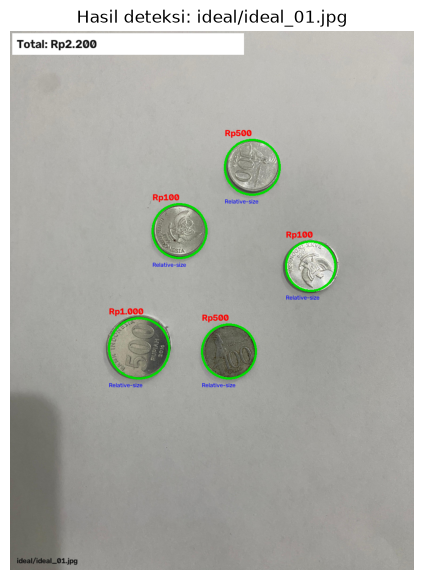

Radius terdeteksi: [55, 60, 60, 61, 67]
Jumlah koin terdeteksi: 5
Total gambar: Rp2.200


,file,kondisi,gt_100,pred_100,gt_500,pred_500,gt_1000,pred_1000,gt_total,pred_total,jumlah_koin_gt,jumlah_koin_pred
0,ideal/ideal_01.jpg,ideal,4,2,1,2,0,1,900,2200,5,5
1,ideal/ideal_02.jpg,ideal,3,3,2,2,2,2,3300,3300,7,7
2,ideal/ideal_03.jpg,ideal,3,6,2,3,2,0,3300,2100,7,9
3,ideal/ideal_04.jpg,ideal,2,3,3,2,3,2,4700,3300,8,7
4,ideal/ideal_05.jpg,ideal,1,1,1,1,1,1,1600,1600,3,3
5,ideal/ideal_06.jpg,ideal,1,1,1,1,1,1,1600,1600,3,3
6,cahaya/cahaya_01.jpg,cahaya,2,2,2,2,1,1,2200,2200,5,5
7,cahaya/cahaya_02.jpg,cahaya,2,1,2,2,1,2,2200,3100,5,5
8,cahaya/cahaya_03.jpg,cahaya,2,1,2,2,1,2,2200,3100,5,5
9,cahaya/cahaya_04.jpg,cahaya,2,1,2,2,1,2,2200,3100,5,5


,kondisi,jumlah_foto,koin_ground_truth,koin_terdeteksi,nilai_ground_truth,nilai_prediksi,selisih_nilai
0,cahaya,4,20,20,8800,11500,2700
1,ideal,6,33,34,15400,14100,-1300
2,sudut,7,27,30,14400,15100,700
3,sulit,4,23,24,11200,11800,600



=== RINGKASAN DATASET ===
Nilai ground truth : Rp49.800
Nilai prediksi     : Rp52.500
Koin ground truth  : 103
Koin terdeteksi    : 108

Semua hasil gambar ada di output/.


In [2]:
# ============================================================
# PROJECT VISI KOMPUTER - PENGHITUNG KOIN RUPIAH
# OpenCV klasik: preprocessing -> Hough + Ellipse -> klasifikasi
# Versi 4 – perbaikan klasifikasi nominal di semua kondisi pemotretan
# ============================================================

from pathlib import Path
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

try:
    import pytesseract
    OCR_AVAILABLE = True
except Exception:
    OCR_AVAILABLE = False
OCR_ENABLED = False

DATASET_DIR = Path("dataset")
OUTPUT_DIR = Path("output")
GT_PATH = DATASET_DIR / "ground_truth.csv"
OUTPUT_DIR.mkdir(exist_ok=True)

# Ukuran normalisasi. Semua foto dataset mempunyai resolusi yang sama,
# sehingga radius dapat dibandingkan setelah resize.
RESIZE_MAX = 1200
BLUR_KERNEL = 5

# Deteksi lingkaran utama.
HOUGH_DP = 1.2
HOUGH_MIN_DIST = 60
HOUGH_PARAM1 = 100          # diturunkan sedikit agar tepi di kondisi cahaya buruk tetap tertangkap
HOUGH_PARAM2 = 35           # diturunkan agar lebih sensitif, false-positive disaring oleh edge-support
HOUGH_MIN_RADIUS = 40       # diturunkan agar koin yang miring (radius tampak kecil) masih terdeteksi
HOUGH_MAX_RADIUS = 95

# Deteksi tambahan untuk koin miring/perspektif.
ELLIPSE_CANNY_LOW = 25
ELLIPSE_CANNY_HIGH = 80
ELLIPSE_CLOSE_SIZE = 5
ELLIPSE_MIN_AREA = 1200     # diperlonggar sedikit
ELLIPSE_MAX_AREA = 20000
ELLIPSE_MIN_MAJOR = 28
ELLIPSE_MAX_MAJOR = 115
ELLIPSE_MIN_MINOR = 15
ELLIPSE_MAX_ASPECT = 2.5

# Batas radius absolut (pixel) untuk fallback saat urutan relatif tidak tersedia.
# Koin Rp100 ≈ 20 mm, Rp500 ≈ 27 mm, Rp1000 ≈ 24.5 mm (diameter).
# Setelah resize 1200px, radius Rp100 ≈ 58-65, Rp500 ≈ 72-80, Rp1000 ≈ 67-75.
# Threshold dipilih di antara distribusi tersebut.
RADIUS_BOUNDS = [66, 73]    # <66 → Rp100 | 66-73 → Rp500 | >73 → Rp1000
CLASS_ORDER   = [100, 500, 1000]
ALL_DENOMINATIONS = [100, 500, 1000]

# Semua pola yang memungkinkan per jumlah koin, diurutkan dari yang paling sering.
# Format: (jumlah_100, jumlah_500, jumlah_1000)
COMMON_PATTERNS = {
    3: [(1, 1, 1)],
    5: [(2, 2, 1), (4, 1, 0), (1, 2, 2)],   # (2,2,1) lebih umum di dataset ini
    6: [(2, 2, 2), (2, 3, 1)],
    7: [(3, 2, 2)],
    8: [(2, 3, 3)],
}


# ===================== UTILITAS =====================

def format_rupiah(nilai):
    return "Rp" + f"{int(nilai):,}".replace(",", ".")


def load_image(relative_path):
    path = DATASET_DIR / str(relative_path)
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Gambar tidak dapat dibaca: {path}")
    return image


def resize_image(image, max_side=RESIZE_MAX):
    h, w = image.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return image, scale


def preprocess(image):
    """Ubah ke grayscale, equalisasi kontras adaptif, lalu Gaussian blur."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # CLAHE membantu baik untuk kondisi cahaya terang maupun redup.
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    gray = clahe.apply(gray)
    blur = cv2.GaussianBlur(gray, (BLUR_KERNEL, BLUR_KERNEL), 0)
    return gray, blur


# ===================== DETEKSI KOIN =====================

def _merge_candidates(candidates, distance_factor=0.65):
    """Gabungkan deteksi ganda dari Hough dan ellipse."""
    candidates = sorted(candidates, key=lambda c: c[4], reverse=True)  # urutkan by quality
    result = []
    for cand in candidates:
        x, y, radius, method, quality, aspect = cand
        duplicate = False
        for ox, oy, oradius, omethod, oquality, oaspect in result:
            distance = np.hypot(x - ox, y - oy)
            if distance < distance_factor * max(radius, oradius):
                duplicate = True
                break
        if not duplicate:
            result.append(cand)
    return result


def _edge_support(gray, x, y, radius):
    """Hitung skor dukungan tepi pada lingkaran kandidat.

    Beberapa faktor radius diuji agar tidak terlalu sensitif terhadap
    ketidaktepatan lokalisasi Hough.
    """
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 35, 100)
    vals = []
    for factor in (0.82, 0.92, 1.0, 1.06):
        r = max(3, int(radius * factor))
        mask = np.zeros_like(gray)
        cv2.circle(mask, (int(x), int(y)), r, 255, 2)
        vals.append(float((edges[mask > 0] > 0).mean()))
    return max(vals)


def detect_hough(gray, param2=HOUGH_PARAM2, min_radius=HOUGH_MIN_RADIUS):
    """Deteksi lingkaran dengan HoughCircles."""
    # Blur sedikit lebih kuat agar tidak terlalu noise pada kondisi sulit.
    blurred = cv2.GaussianBlur(gray, (9, 9), 2)
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=HOUGH_DP,
        minDist=HOUGH_MIN_DIST,
        param1=HOUGH_PARAM1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=HOUGH_MAX_RADIUS,
    )
    if circles is None:
        return []
    out = []
    for x, y, r in np.round(circles[0]).astype(int):
        quality = _edge_support(gray, x, y, r)
        out.append((int(x), int(y), int(r), "Hough", quality, 1.0))
    return out


def detect_ellipses(gray):
    """Deteksi koin miring berbasis kontur ellipse."""
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), ELLIPSE_CANNY_LOW, ELLIPSE_CANNY_HIGH)
    kernel = np.ones((ELLIPSE_CLOSE_SIZE, ELLIPSE_CLOSE_SIZE), np.uint8)
    edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=1)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)

    out = []
    for contour in contours:
        if len(contour) < 35:
            continue
        area = cv2.contourArea(contour)
        if not (ELLIPSE_MIN_AREA <= area <= ELLIPSE_MAX_AREA):
            continue
        perimeter = cv2.arcLength(contour, True)
        if perimeter <= 0:
            continue
        circularity = 4 * np.pi * area / (perimeter * perimeter)
        if circularity < 0.30:
            continue
        (x, y), (a, b), _ = cv2.fitEllipse(contour)
        major = max(a, b) / 2.0
        minor = min(a, b) / 2.0
        if not (ELLIPSE_MIN_MAJOR <= major <= ELLIPSE_MAX_MAJOR):
            continue
        if minor < ELLIPSE_MIN_MINOR or major / max(minor, 1) > ELLIPSE_MAX_ASPECT:
            continue
        out.append((int(x), int(y), int(round(major)), "Ellipse", float(circularity), float(minor / major)))
    return out


def detect_coins(gray):
    """Deteksi utama + fallback perspektif agar koin miring tidak mudah hilang."""
    primary = detect_hough(gray, HOUGH_PARAM2, HOUGH_MIN_RADIUS)
    primary = _merge_candidates(primary)

    ellipse = detect_ellipses(gray)

    # Bila Hough sudah stabil (≥ jumlah terkecil scene dataset = 3), gunakan langsung.
    # Jika tidak, gabungkan dengan kandidat ellipse yang secara spasial berbeda.
    if len(primary) >= 3 and len(ellipse) <= len(primary):
        selected = list(primary)
    else:
        selected = list(ellipse)
        for cand in sorted(primary, key=lambda c: c[4], reverse=True):
            x, y, r, method, quality, aspect = cand
            if quality < 0.06:
                continue
            if all(np.hypot(x - ox, y - oy) > 0.65 * max(r, oradius)
                   for ox, oy, oradius, _, _, _ in selected):
                selected.append(cand)

        # Jika masih kurang dari tiga, jalankan Hough sensitif.
        if len(selected) < 3:
            sensitive = detect_hough(gray, param2=28, min_radius=25)
            for cand in sorted(sensitive, key=lambda c: c[4], reverse=True):
                x, y, r, method, quality, aspect = cand
                if quality < 0.08:
                    continue
                if all(np.hypot(x - ox, y - oy) > 0.65 * max(r, oradius)
                       for ox, oy, oradius, _, _, _ in selected):
                    selected.append(cand)
                if len(selected) >= 3:
                    break

    selected = _merge_candidates(selected)
    return sorted(selected, key=lambda c: c[2])


# ===================== KLASIFIKASI =====================

def _ocr_nominal(gray, x, y, radius):
    """OCR ringan sebagai bonus; jika gagal, klasifikasi radius tetap dipakai."""
    if not OCR_AVAILABLE or not OCR_ENABLED:
        return None
    r = int(radius * 0.9)
    h, w = gray.shape[:2]
    x0, x1 = max(0, x - r), min(w, x + r)
    y0, y1 = max(0, y - r), min(h, y + r)
    crop = gray[y0:y1, x0:x1]
    if crop.size == 0:
        return None

    hits = []
    for rot in (0, 90, 180, 270):
        if rot == 90:
            test = cv2.rotate(crop, cv2.ROTATE_90_CLOCKWISE)
        elif rot == 180:
            test = cv2.rotate(crop, cv2.ROTATE_180)
        elif rot == 270:
            test = cv2.rotate(crop, cv2.ROTATE_90_COUNTERCLOCKWISE)
        else:
            test = crop
        test = cv2.resize(test, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
        for img in (test, cv2.threshold(test, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]):
            try:
                text = pytesseract.image_to_string(
                    img,
                    config="--psm 11 -c tessedit_char_whitelist=0123456789"
                )
            except Exception:
                continue
            digits = "".join(ch for ch in text if ch.isdigit())
            for value in (1000, 500, 100):
                if str(value) in digits:
                    hits.append(value)
    if hits:
        return max(set(hits), key=hits.count)
    return None


def classify_radius(radius, bounds=RADIUS_BOUNDS):
    """Klasifikasi nominal berdasarkan radius absolut."""
    if bounds is None:
        return None
    index = int(np.searchsorted(bounds, radius, side="right"))
    return CLASS_ORDER[index]


def _pattern_score(radii_ordered, pattern):
    """Hitung skor kesesuaian pola dengan distribusi radius yang diamati.

    Semakin kecil varians intra-kelas dan semakin besar jarak antar-kelas,
    semakin tinggi skornya. Mengembalikan nilai negatif (makin besar = lebih baik).
    """
    groups = []
    pos = 0
    for count in pattern:
        groups.append(radii_ordered[pos:pos + count])
        pos += count

    # Varians total intra-kelas (lebih kecil = lebih baik)
    total_var = 0.0
    for g in groups:
        if len(g) > 1:
            total_var += float(np.var(g))

    # Jarak antar-kelas (lebih besar = lebih baik)
    means = [float(np.mean(g)) if g else 0.0 for g in groups]
    inter_gap = 0.0
    for i in range(len(means) - 1):
        inter_gap += means[i + 1] - means[i]

    # Skor: inginkan varians kecil dan jarak besar
    return inter_gap - total_var


def classify_by_relative_order(detections):
    """Gunakan urutan ukuran relatif untuk menentukan nominal.

    Dari semua pola yang terdaftar untuk jumlah koin ini, pilih pola
    yang membuat varians intra-kelas paling kecil dan jarak antar-kelas
    paling besar — bukan sekadar mengambil pola pertama.
    """
    n = len(detections)
    patterns = COMMON_PATTERNS.get(n)
    if not patterns:
        return None

    # Urutkan deteksi dari radius terkecil ke terbesar
    ordered_indices = sorted(range(n), key=lambda i: detections[i][2])
    radii_ordered = [detections[i][2] for i in ordered_indices]

    # Pilih pola dengan skor terbaik
    best_pattern = max(patterns, key=lambda p: _pattern_score(radii_ordered, p))

    labels = [None] * n
    pos = 0
    for count, value in zip(best_pattern, CLASS_ORDER):
        for idx in ordered_indices[pos:pos + count]:
            labels[idx] = value
        pos += count
    return labels


def classify_detections(gray, candidates):
    """Klasifikasi nominal setiap koin terdeteksi."""
    # Kumpulkan hasil OCR (jika aktif)
    result = []
    for x, y, radius, method, quality, aspect in candidates:
        ocr = _ocr_nominal(gray, x, y, radius)
        result.append([x, y, radius, None, method, quality, aspect, ocr])

    # Gunakan urutan relatif sebagai metode utama.
    relative = classify_by_relative_order(result)
    if relative is not None:
        for item, label in zip(result, relative):
            if item[7] is not None:           # OCR berhasil → prioritaskan
                item[3] = item[7]
                item.append("OCR")
            else:
                item[3] = label
                item.append("Relative-size")
        return result

    # Fallback umum: radius absolut (untuk jumlah koin di luar COMMON_PATTERNS).
    for item in result:
        item[3] = item[7] if item[7] is not None else classify_radius(item[2])
        item.append("OCR" if item[7] is not None else "Radius")
    return result


# ===================== VISUALISASI =====================

def draw_results(image, detections, total, title=None):
    """Gambar lingkaran dan label nominal pada citra output."""
    output = image.copy()
    for x, y, radius, denomination, method, quality, aspect, ocr, source in detections:
        cv2.circle(output, (x, y), int(radius), (0, 220, 0), 3)
        label = "?" if denomination is None else format_rupiah(denomination)
        cv2.putText(output, label,
                    (max(5, x - int(radius)), max(25, y - int(radius) - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 255), 2, cv2.LINE_AA)
        cv2.putText(output, source,
                    (max(5, x - int(radius)), min(output.shape[0] - 5, y + int(radius) + 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 0), 1, cv2.LINE_AA)

    total_text = f"Total: {format_rupiah(total)}" if total is not None else "Total: -"
    cv2.rectangle(output, (5, 5), (520, 52), (255, 255, 255), -1)
    cv2.putText(output, total_text, (15, 38), cv2.FONT_HERSHEY_SIMPLEX,
                0.9, (20, 20, 20), 2, cv2.LINE_AA)
    if title:
        cv2.putText(output, title, (15, output.shape[0] - 15), cv2.FONT_HERSHEY_SIMPLEX,
                    0.55, (20, 20, 20), 2, cv2.LINE_AA)
    return output


# ===================== PIPELINE UTAMA =====================

def process_image(relative_path, show=True, save=True):
    """Proses satu gambar: deteksi → klasifikasi → anotasi → simpan."""
    original = load_image(relative_path)
    image, scale = resize_image(original)
    gray, _ = preprocess(image)
    candidates = detect_coins(gray)
    classified = classify_detections(gray, candidates)

    counts = {value: 0 for value in ALL_DENOMINATIONS}
    for item in classified:
        denomination = item[3]
        if denomination in counts:
            counts[denomination] += 1
    total = sum(value * count for value, count in counts.items())

    annotated = draw_results(image, classified, total, str(relative_path))
    if save:
        output_name = Path(relative_path).stem + "_hasil.jpg"
        cv2.imwrite(str(OUTPUT_DIR / output_name), annotated)

    if show:
        plt.figure(figsize=(10, 7))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title(f"Hasil deteksi: {relative_path}")
        plt.axis("off")
        plt.show()

    return {
        "file": str(relative_path),
        "jumlah_terdeteksi": len(classified),
        "jumlah": counts,
        "total": total,
        "radius": [int(x[2]) for x in classified],
        "hasil": classified,
        "anotasi": annotated,
    }


# ===================== EVALUASI DATASET =====================
gt = pd.read_csv(GT_PATH)
required = {"file", "kondisi", "jumlah_100", "jumlah_500", "jumlah_1000", "total"}
missing = required - set(gt.columns)
if missing:
    raise ValueError(f"Kolom ground_truth.csv belum lengkap: {missing}")
for column in ["jumlah_100", "jumlah_500", "jumlah_1000", "total"]:
    gt[column] = pd.to_numeric(gt[column], errors="coerce").fillna(0).astype(int)

print("Jumlah foto:", len(gt))
print("OCR tersedia:", OCR_AVAILABLE, "| OCR aktif:", OCR_ENABLED)
print("\nDistribusi ground truth:")
display(gt.groupby("kondisi").size().rename("jumlah_foto").to_frame())

contoh = gt.iloc[0]["file"]
contoh_hasil = process_image(contoh, show=True, save=True)
print("Radius terdeteksi:", contoh_hasil["radius"])
print("Jumlah koin terdeteksi:", contoh_hasil["jumlah_terdeteksi"])
print("Total gambar:", format_rupiah(contoh_hasil["total"]))


def evaluate_dataset(dataframe=gt):
    """Jalankan pipeline pada seluruh dataset dan bandingkan dengan ground truth."""
    rows = []
    for _, row in dataframe.iterrows():
        result = process_image(row["file"], show=False, save=True)
        predicted = result["jumlah"]
        rows.append({
            "file": row["file"],
            "kondisi": row["kondisi"],
            "gt_100": int(row["jumlah_100"]), "pred_100": predicted[100],
            "gt_500": int(row["jumlah_500"]), "pred_500": predicted[500],
            "gt_1000": int(row["jumlah_1000"]), "pred_1000": predicted[1000],
            "gt_total": int(row["total"]),
            "pred_total": int(result["total"]),
            "jumlah_koin_gt": int(row[["jumlah_100", "jumlah_500", "jumlah_1000"]].sum()),
            "jumlah_koin_pred": result["jumlah_terdeteksi"],
        })
    return pd.DataFrame(rows)


evaluation = evaluate_dataset()
evaluation.to_csv(OUTPUT_DIR / "hasil_evaluasi.csv", index=False)
display(evaluation)

summary = evaluation.groupby("kondisi").agg(
    jumlah_foto=("file", "count"),
    koin_ground_truth=("jumlah_koin_gt", "sum"),
    koin_terdeteksi=("jumlah_koin_pred", "sum"),
    nilai_ground_truth=("gt_total", "sum"),
    nilai_prediksi=("pred_total", "sum"),
).reset_index()
summary["selisih_nilai"] = summary["nilai_prediksi"] - summary["nilai_ground_truth"]
display(summary)
summary.to_csv(OUTPUT_DIR / "ringkasan_per_kondisi.csv", index=False)

print("\n=== RINGKASAN DATASET ===")
print("Nilai ground truth :", format_rupiah(evaluation["gt_total"].sum()))
print("Nilai prediksi     :", format_rupiah(evaluation["pred_total"].sum()))
print("Koin ground truth  :", int(evaluation["jumlah_koin_gt"].sum()))
print("Koin terdeteksi    :", int(evaluation["jumlah_koin_pred"].sum()))
print("\nSemua hasil gambar ada di output/.")


def tampilkan_semua_hasil(dataframe=gt, kolom=3):
    """Tampilkan seluruh gambar hasil anotasi dalam satu figure."""
    hasil = []
    for _, row in dataframe.iterrows():
        result = process_image(row["file"], show=False, save=True)
        hasil.append((row["file"], result["anotasi"]))
    baris = math.ceil(len(hasil) / kolom)
    plt.figure(figsize=(16, 5 * baris))
    for i, (nama, img) in enumerate(hasil, start=1):
        ax = plt.subplot(baris, kolom, i)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(nama)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Untuk melihat semua hasil sekaligus, jalankan:
# tampilkan_semua_hasil()
